# 02 – Depth back-projection and multi-view alignment (Milestone 2)

For each valid depth pixel with center $(u+0.5,\ v+0.5)$ and depth $d$:

$$p_\text{cam} = d\,K^{-1}\begin{bmatrix}u+0.5\\ v+0.5\\ 1\end{bmatrix},\qquad
p_\text{world} = R\,p_\text{cam} + t,\quad \begin{bmatrix}R & t\\ 0 & 1\end{bmatrix} = T_\text{cam→world}$$

Implementation: `src/volumetric_reasoning/geometry/backprojection.py` (synthetic tests in `tests/test_backprojection.py`).

**Checks in this notebook**
1. A single frame back-projects to a plausible 3D shape.
2. Points from different frames overlap (coloring by frame should show no doubled walls).
3. Quantitatively: distance of every point to the laser-scan mesh, as a function of depth → choose `max_depth`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import open3d as o3d

from volumetric_reasoning.config import load_config, resolve_path
from volumetric_reasoning.datasets import ScanNetPPIphoneScene
from volumetric_reasoning.geometry.backprojection import depth_to_points, frames_to_points
from volumetric_reasoning.geometry.raycast import make_raycasting_scene

# ---- choose the scene here ---------------------------------------------
SCENE_ID = "3e8bba0176"   # None = use dataset.scene_id from configs/default.yaml / local.yaml
# --------------------------------------------------------------------------

cfg = load_config()
if SCENE_ID is not None:
    cfg["dataset"]["scene_id"] = SCENE_ID
scene = ScanNetPPIphoneScene(resolve_path(cfg["dataset"]["root"]), cfg["dataset"]["scene_id"])
frames = scene.load_frames(scene.select_frames(**cfg["frames"]))
mesh = o3d.io.read_triangle_mesh(str(scene.mesh_path))
rc = make_raycasting_scene(mesh)
out_dir = resolve_path(cfg["output"]["root"]) / scene.scene_id
out_dir.mkdir(parents=True, exist_ok=True)
print(len(frames), "frames; outputs ->", out_dir)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
121 frames; outputs -> /Users/kaiglantz/dev/freespace-tokens/outputs/3e8bba0176


## 1. One frame in camera coordinates

frame 3600: 49152 points; x [-1.03, 1.42] y [-1.52, 0.73] z [0.36, 3.52] m


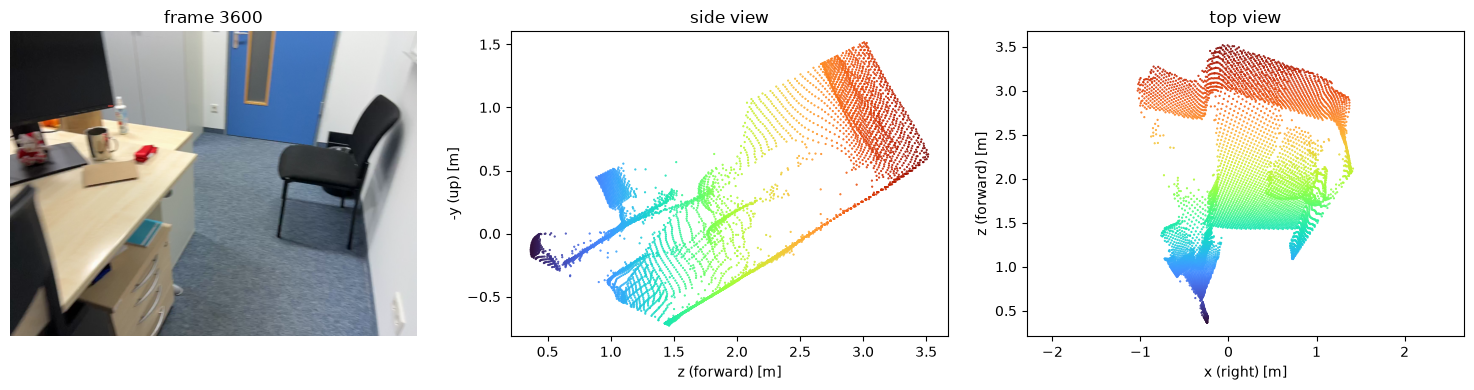

In [2]:
f = frames[len(frames) // 2]
pts_cam, mask = depth_to_points(f.depth, f.K_depth)  # no pose -> camera coordinates
print(f"frame {f.index}: {len(pts_cam)} points; x [{pts_cam[:,0].min():.2f}, {pts_cam[:,0].max():.2f}] "
      f"y [{pts_cam[:,1].min():.2f}, {pts_cam[:,1].max():.2f}] z [{pts_cam[:,2].min():.2f}, {pts_cam[:,2].max():.2f}] m")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(f.rgb); ax[0].set_title(f"frame {f.index}"); ax[0].axis("off")
# Side view (z forward, -y up) and top view (x right, z forward) of the camera-space points.
sub = pts_cam[::7]
ax[1].scatter(sub[:, 2], -sub[:, 1], s=0.3, c=sub[:, 2], cmap="turbo"); ax[1].set_xlabel("z (forward) [m]"); ax[1].set_ylabel("-y (up) [m]")
ax[1].set_title("side view"); ax[1].axis("equal")
ax[2].scatter(sub[:, 0], sub[:, 2], s=0.3, c=sub[:, 2], cmap="turbo"); ax[2].set_xlabel("x (right) [m]"); ax[2].set_ylabel("z (forward) [m]")
ax[2].set_title("top view"); ax[2].axis("equal")
plt.tight_layout()

## 2. Distance to the laser mesh vs. depth

All depth values (no cutoff) → world points → unsigned distance to the reference mesh.
Points seen through windows have no laser geometry behind them and therefore get large distances.

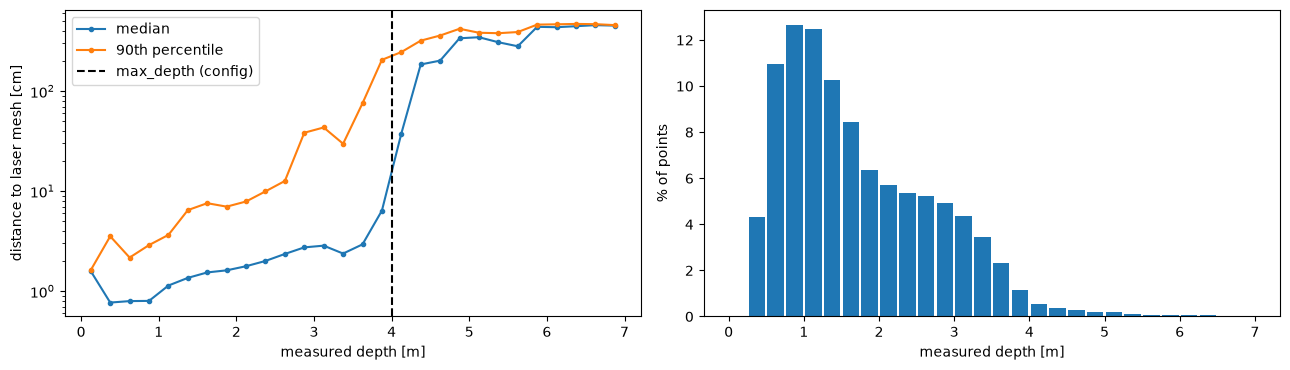

In [3]:
pts_all, _, _ = frames_to_points(frames)  # no depth cutoff
depth_all = np.concatenate([fr.depth[fr.depth > 0] for fr in frames])  # same order as pts_all
dist = rc.compute_distance(o3d.core.Tensor(pts_all.astype(np.float32))).numpy()

bins = np.arange(0, 7.01, 0.25)
centers = (bins[:-1] + bins[1:]) / 2
which = np.digitize(depth_all, bins) - 1
med = [np.median(dist[which == i]) if (which == i).any() else np.nan for i in range(len(centers))]
p90 = [np.percentile(dist[which == i], 90) if (which == i).any() else np.nan for i in range(len(centers))]
cnt = np.bincount(which.clip(0, len(centers) - 1), minlength=len(centers))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].semilogy(centers, np.array(med) * 100, ".-", label="median")
ax[0].semilogy(centers, np.array(p90) * 100, ".-", label="90th percentile")
ax[0].axvline(cfg["depth"]["max_depth"], color="k", ls="--", label="max_depth (config)")
ax[0].set_xlabel("measured depth [m]"); ax[0].set_ylabel("distance to laser mesh [cm]"); ax[0].legend()
ax[1].bar(centers, cnt / cnt.sum() * 100, width=0.22); ax[1].set_xlabel("measured depth [m]"); ax[1].set_ylabel("% of points")
plt.tight_layout()

## 3. Combined point cloud with depth cutoff

5,828,289 points from 121 frames (depth in (0.1, 4.0] m)
distance to laser mesh: median 1.4 cm, 90th pct 7.0 cm, > 10 cm: 7.5%


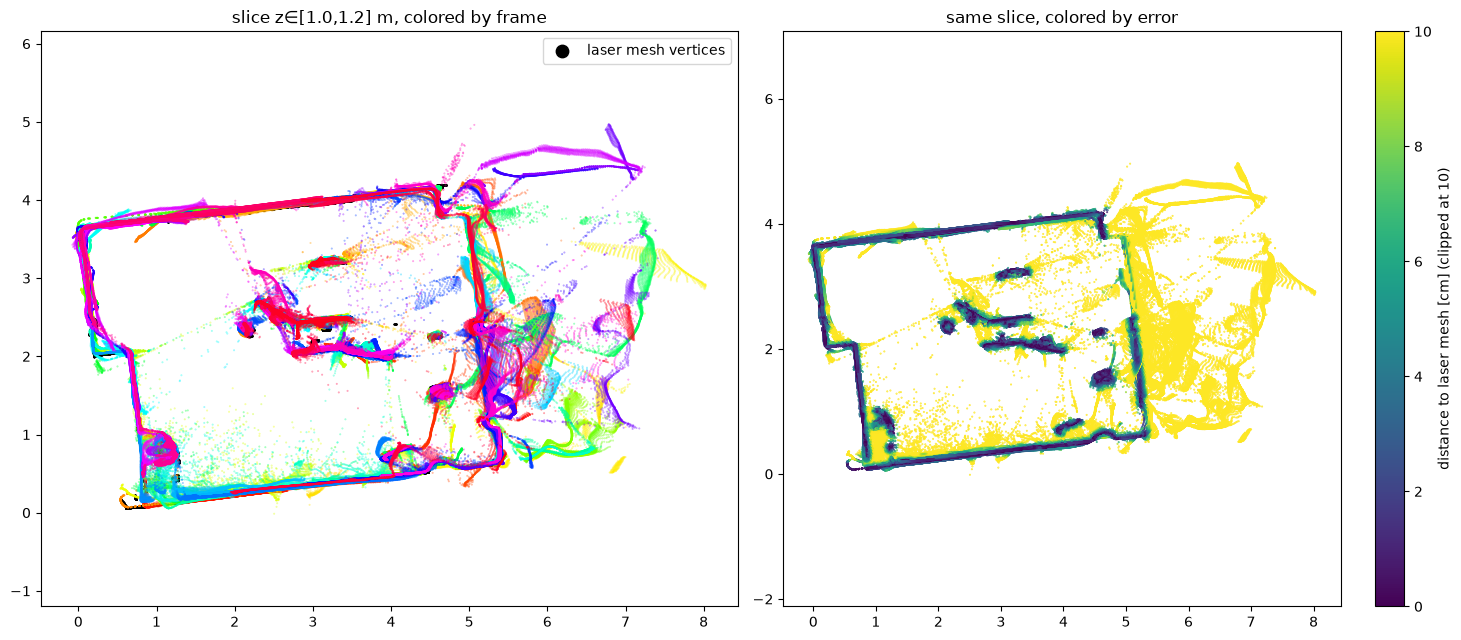

In [4]:
dmin, dmax = cfg["depth"]["min_depth"], cfg["depth"]["max_depth"]
points, colors, frame_ids = frames_to_points(frames, min_depth=dmin, max_depth=dmax)
dist = rc.compute_distance(o3d.core.Tensor(points.astype(np.float32))).numpy()
print(f"{len(points):,} points from {len(frames)} frames (depth in ({dmin}, {dmax}] m)")
print(f"distance to laser mesh: median {np.median(dist)*100:.1f} cm, 90th pct {np.percentile(dist, 90)*100:.1f} cm, "
      f"> 10 cm: {(dist > 0.1).mean()*100:.1f}%")

# Horizontal slice at 1.0-1.2 m height: walls/furniture from all frames should form single thin lines.
z = points[:, 2]
sl = (z > 1.0) & (z < 1.2)
verts = np.asarray(mesh.vertices); vsl = (verts[:, 2] > 1.0) & (verts[:, 2] < 1.2)
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
ax[0].scatter(verts[vsl, 0], verts[vsl, 1], s=0.2, c="k", label="laser mesh vertices")
ax[0].scatter(points[sl, 0], points[sl, 1], s=0.2, c=frame_ids[sl], cmap="hsv", alpha=0.4)
ax[0].set_title("slice z∈[1.0,1.2] m, colored by frame"); ax[0].axis("equal"); ax[0].legend(markerscale=20)
sc = ax[1].scatter(points[sl, 0], points[sl, 1], s=0.2, c=np.minimum(dist[sl], 0.1) * 100, cmap="viridis")
plt.colorbar(sc, ax=ax[1], label="distance to laser mesh [cm] (clipped at 10)")
ax[1].set_title("same slice, colored by error"); ax[1].axis("equal")
plt.tight_layout()

## 4. Save and view in 3D

Writes a voxel-downsampled colored point cloud to `outputs/<scene>/` (git-ignored).
Set `SHOW_3D = True` to open an Open3D window (point cloud colored by RGB). `MAX_HEIGHT` removes everything above
that height so you can look into the room from above. In the window: left-drag rotates, scroll zooms, `+`/`-` changes point size.

In [5]:
pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points))
pcd.colors = o3d.utility.Vector3dVector(colors)
pcd_down = pcd.voxel_down_sample(0.01)
path = out_dir / "backprojected_points.ply"
o3d.io.write_point_cloud(str(path), pcd_down)
print(f"saved {len(pcd_down.points):,} points -> {path}")

SHOW_3D = True
MAX_HEIGHT = 2.0  # meters (world z is up); cut ceiling/upper walls to look into the room. None = no cut
if SHOW_3D:
    view = pcd_down
    if MAX_HEIGHT is not None:
        lo, hi = view.get_min_bound(), view.get_max_bound()
        view = view.crop(o3d.geometry.AxisAlignedBoundingBox([lo[0], lo[1], lo[2]], [hi[0], hi[1], MAX_HEIGHT]))
    o3d.visualization.draw_geometries([view], front=[0.0, -0.4, 1.0], up=[0, 0, 1],
                                      lookat=view.get_center(), zoom=0.6)  # start looking down from above

saved 2,887,098 points -> /Users/kaiglantz/dev/freespace-tokens/outputs/3e8bba0176/backprojected_points.ply


2026-11-05 19:36:54.737 Python[2670:17504] WARNING: Secure coding is automatically enabled for restorable state! However, not on all supported macOS versions of this application. Opt-in to secure coding explicitly by implementing NSApplicationDelegate.applicationSupportsSecureRestorableState:.


## Findings

- Fill in after running: are walls single lines in the slice? Where are the largest errors?
- Next (Milestone 3): TSDF fusion of the same frames.